- From all possible parameter configurations try PCA
- Use Elisa's paper to try different n values for different neuron types
- Sparsity test on the two subsets of eigenvectors
- Plot y_average for a range of inputs x=0 to 2

In [7]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax


# set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

In [1]:
# find mitral output using solved g
# currently without granule cell
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)

    base_y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)

    return r, g, b, base_y  # Return base_y as y (granule cell computation is commented out)


# solve fixed point via Anderson - return g
# Use the local mitral_fixed_point function
def solve_fixed_point(theta, x, m):
    # Unpack all parameters needed for mitral_fixed_point
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Local mitral_fixed_point signature: (g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    g_fixed = solution.params
    return g_fixed

# fixed-point function
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """
    Fixed point equation for green neurons
    """
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)

    return g_new


# unpack parameter
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m  # Matrix: cross-channel connections g->r
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m  # Matrix: cross-channel connections g->y (was W_g_m)
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)


In [6]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [8]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


Number of surviving samples: 982
Number of dimensions: 28

PCA Results:
First 10 principal components explain 0.7820 (78.20%) of variance
First 5 principal components explain 0.5211 (52.11%) of variance
First 3 principal components explain 0.3698 (36.98%) of variance
Components needed for 80% variance: 11
Components needed for 90% variance: 14
Components needed for 95% variance: 17
Components needed for 99% variance: 21


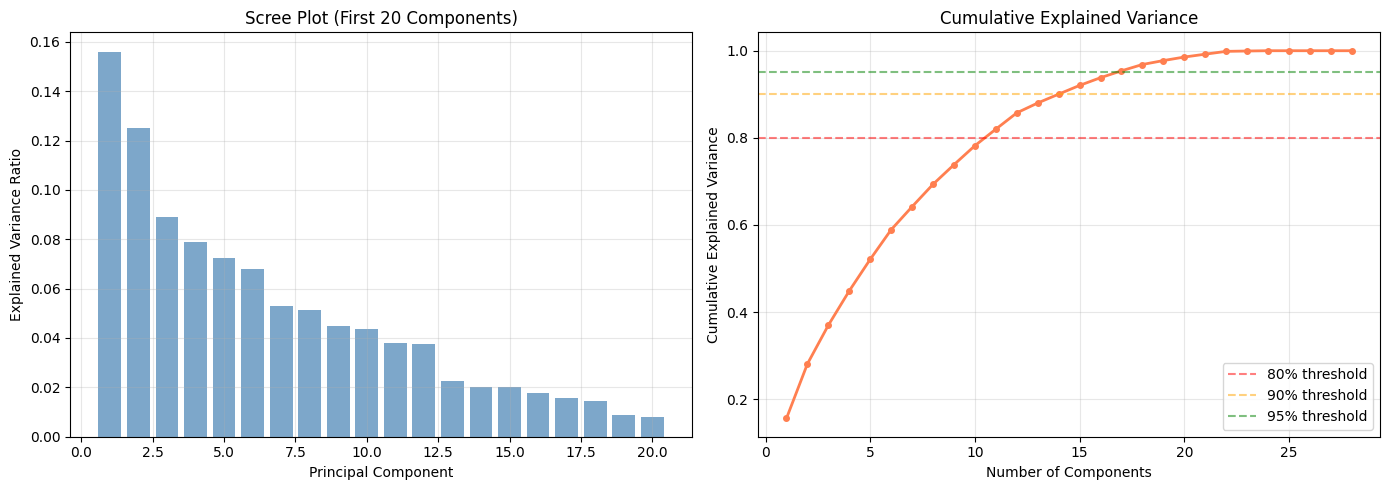

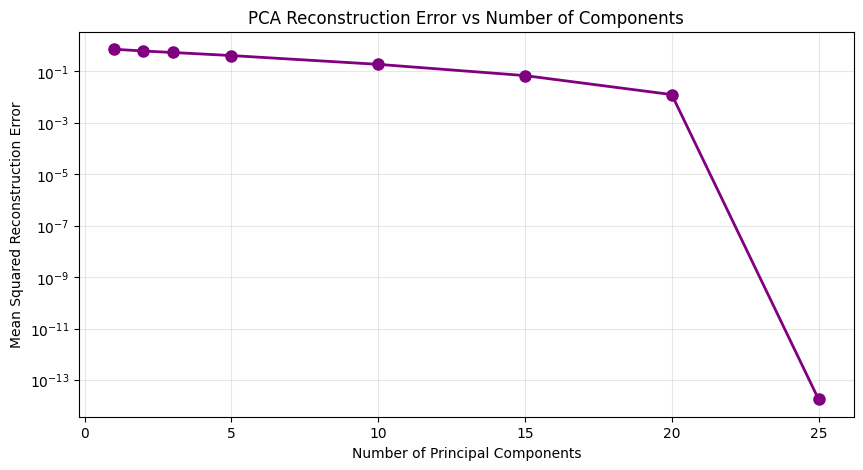


Reconstruction Errors:
  1 components: MSE = 0.723409
  2 components: MSE = 0.616278
  3 components: MSE = 0.540130
  5 components: MSE = 0.410473
  10 components: MSE = 0.186891
  15 components: MSE = 0.068317
  20 components: MSE = 0.012464
  25 components: MSE = 0.000000


In [10]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize the data before PCA (important for PCA)
scaler = StandardScaler()
theta_opt_scaled = scaler.fit_transform(theta_opt)

# Perform PCA
pca = PCA()
theta_opt_pca = pca.fit_transform(theta_opt_scaled)

# Evaluate PCA quality
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Print summary statistics
print(f"Number of surviving samples: {theta_opt.shape[0]}")
print(f"Number of dimensions: {theta_opt.shape[1]}")
print(f"\nPCA Results:")
print(f"First 10 principal components explain {cumulative_variance[9]:.4f} ({cumulative_variance[9]*100:.2f}%) of variance")
print(f"First 5 principal components explain {cumulative_variance[4]:.4f} ({cumulative_variance[4]*100:.2f}%) of variance")
print(f"First 3 principal components explain {cumulative_variance[2]:.4f} ({cumulative_variance[2]*100:.2f}%) of variance")

# Find number of components needed for different variance thresholds
for threshold in [0.8, 0.9, 0.95, 0.99]:
    n_components = np.argmax(cumulative_variance >= threshold) + 1
    print(f"Components needed for {threshold*100:.0f}% variance: {n_components}")

# Plot explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Scree plot (explained variance per component)
axes[0].bar(range(1, min(21, len(explained_variance_ratio) + 1)), 
            explained_variance_ratio[:20], alpha=0.7, color='steelblue')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot (First 20 Components)')
axes[0].grid(True, alpha=0.3)

# Plot 2: Cumulative explained variance
axes[1].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 
             marker='o', linewidth=2, markersize=4, color='coral')
axes[1].axhline(y=0.8, color='r', linestyle='--', alpha=0.5, label='80% threshold')
axes[1].axhline(y=0.9, color='orange', linestyle='--', alpha=0.5, label='90% threshold')
axes[1].axhline(y=0.95, color='g', linestyle='--', alpha=0.5, label='95% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate reconstruction error for different numbers of components
reconstruction_errors = []
n_components_to_test = [1, 2, 3, 5, 10, 15, 20, min(25, theta_opt.shape[1])]

for n_comp in n_components_to_test:
    if n_comp > theta_opt.shape[1]:
        continue
    pca_n = PCA(n_components=n_comp)
    theta_opt_pca_n = pca_n.fit_transform(theta_opt_scaled)
    theta_opt_reconstructed = pca_n.inverse_transform(theta_opt_pca_n)
    
    # Calculate mean squared error
    mse = np.mean((theta_opt_scaled - theta_opt_reconstructed) ** 2)
    reconstruction_errors.append(mse)

# Plot reconstruction error
plt.figure(figsize=(10, 5))
plt.plot(n_components_to_test[:len(reconstruction_errors)], reconstruction_errors, 
         marker='o', linewidth=2, markersize=8, color='purple')
plt.xlabel('Number of Principal Components')
plt.ylabel('Mean Squared Reconstruction Error')
plt.title('PCA Reconstruction Error vs Number of Components')
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show()

print(f"\nReconstruction Errors:")
for n_comp, error in zip(n_components_to_test[:len(reconstruction_errors)], reconstruction_errors):
    print(f"  {n_comp} components: MSE = {error:.6f}")


## n values